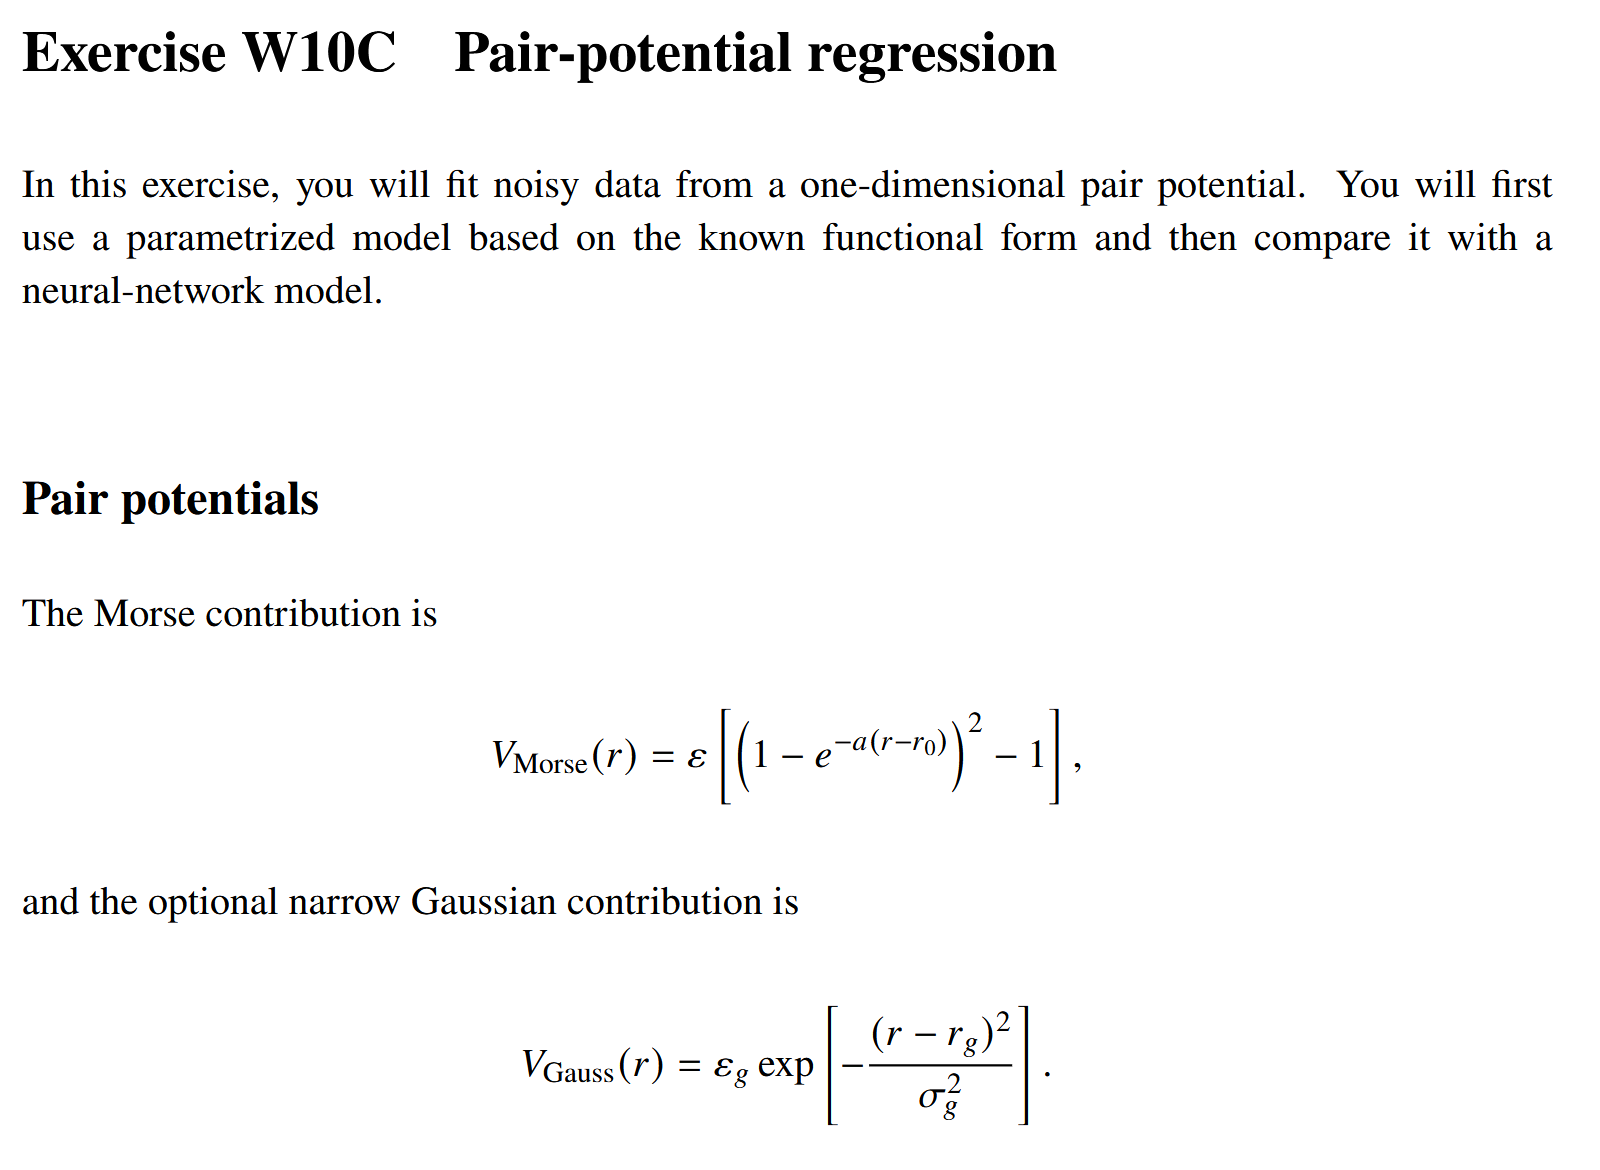
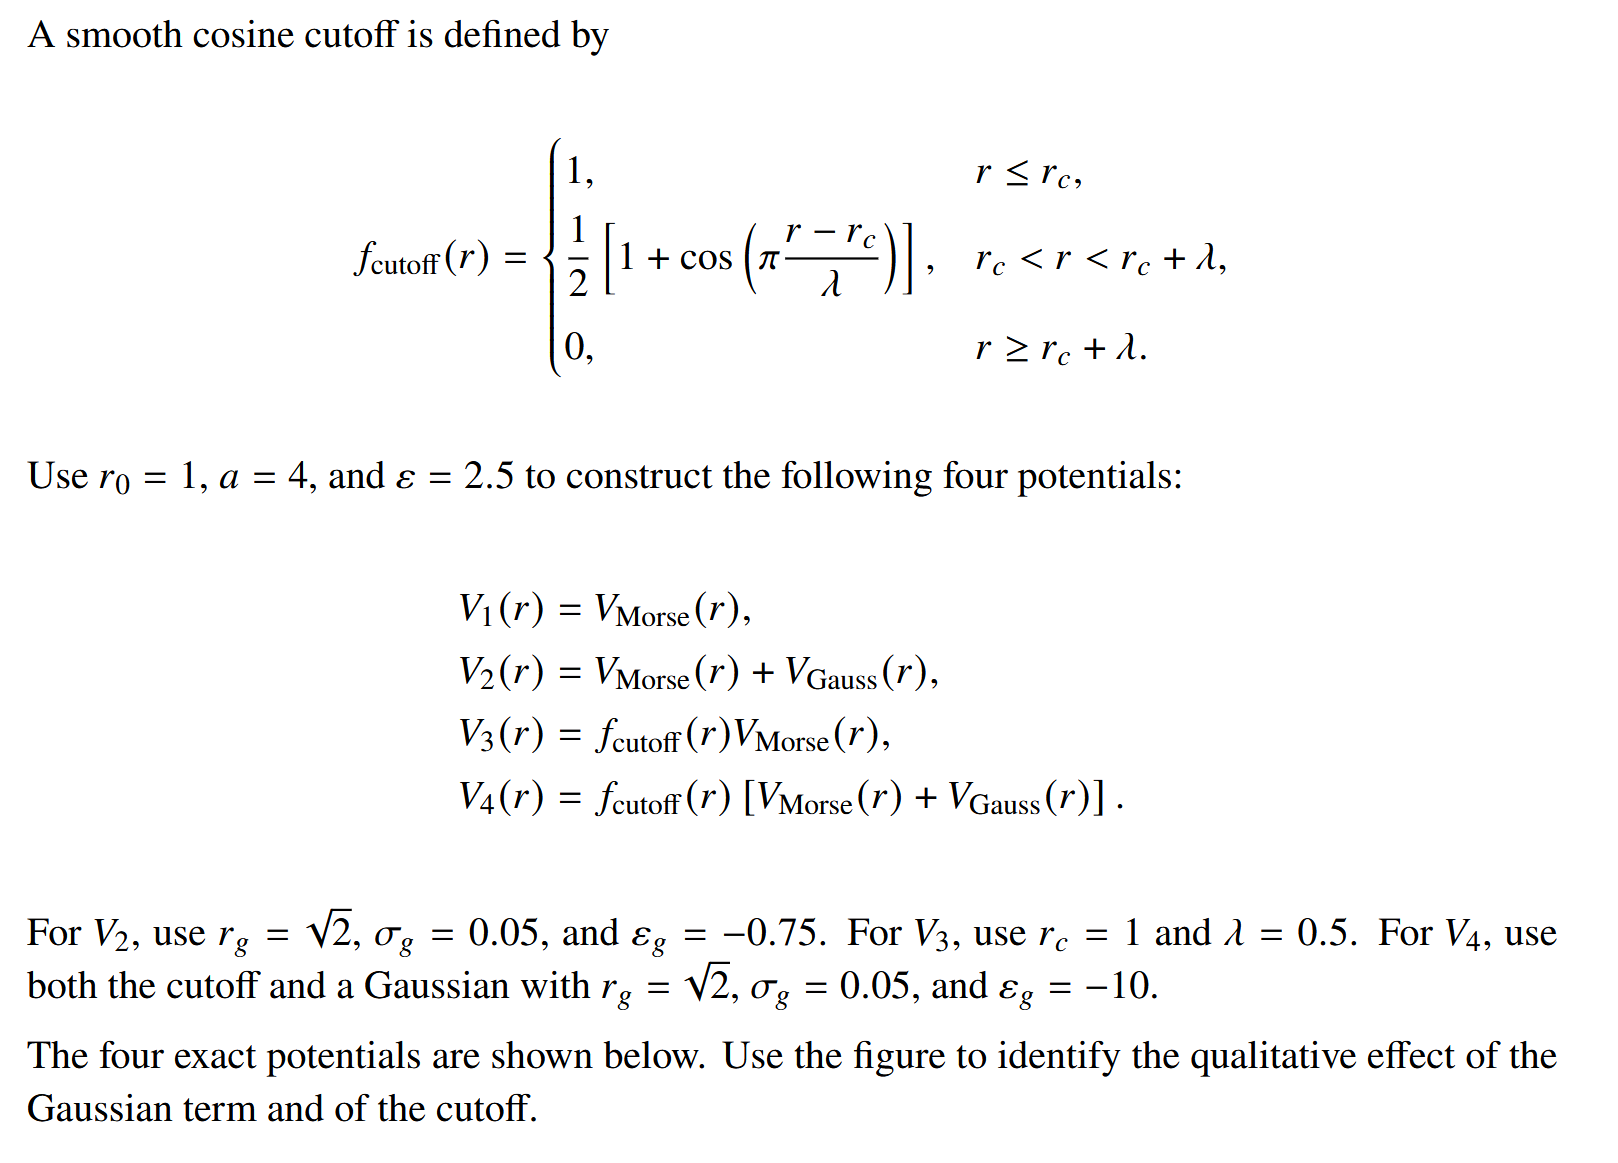

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from models import *

def v_morse(r, r0=1.0, a=4.0, eps=2.5):
    return eps * ((1.0 - torch.exp(-a * (r - r0)))**2 - 1.0)

def v_gauss(r, rg, sigma_g, eps_g):
    return eps_g * torch.exp(-((r - rg)**2) / (sigma_g**2))

def f_cutoff(r, rc=1.0, lambda_=0.5):
    out = torch.zeros_like(r)
    
    out[r <= rc] = 1.0
    
    mask = (r > rc) & (r < rc + lambda_)
    out[mask] = 0.5 * (1.0 + torch.cos(np.pi * (r[mask] - rc) / lambda_))
    
    return out

def V1(r): return v_morse(r)
def V2(r): return v_morse(r) + v_gauss(r, rg=np.sqrt(2), sigma_g=0.05, eps_g=-0.75)
def V3(r): return f_cutoff(r, rc=1.0, lambda_=0.5) * v_morse(r)
def V4(r): return f_cutoff(r, rc=1.0, lambda_=0.5) * (v_morse(r) + v_gauss(r, rg=np.sqrt(2), sigma_g=0.05, eps_g=-10.0))

**Qualitative Effects**

* **The Gaussian Term:** The Gaussian contribution $V_{\text{Gauss}}(r)$ creates a highly localized perturbation centered exactly at $r_g$. Because the assigned values for $\varepsilon_g$ are negative ($-0.75$ and $-10$) and the width $\sigma_g$ is very small ($0.05$), this term manifests as a sharp, narrow downward spike (an attractive potential well) located at $r = \sqrt{2}$.


* **The Cutoff Term:** The smooth cosine cutoff $f_{\text{cutoff}}(r)$ forces the potential energy to smoothly reach exactly zero at a finite distance. While the raw Morse potential approaches zero asymptotically as $r \to \infty$, applying the cutoff leaves the potential entirely unchanged for $r \leq r_c$, smoothly scales it down between $r_c$ and $r_c + \lambda$, and forces it to strictly equal $0$ for all distances $r \geq r_c + \lambda$.

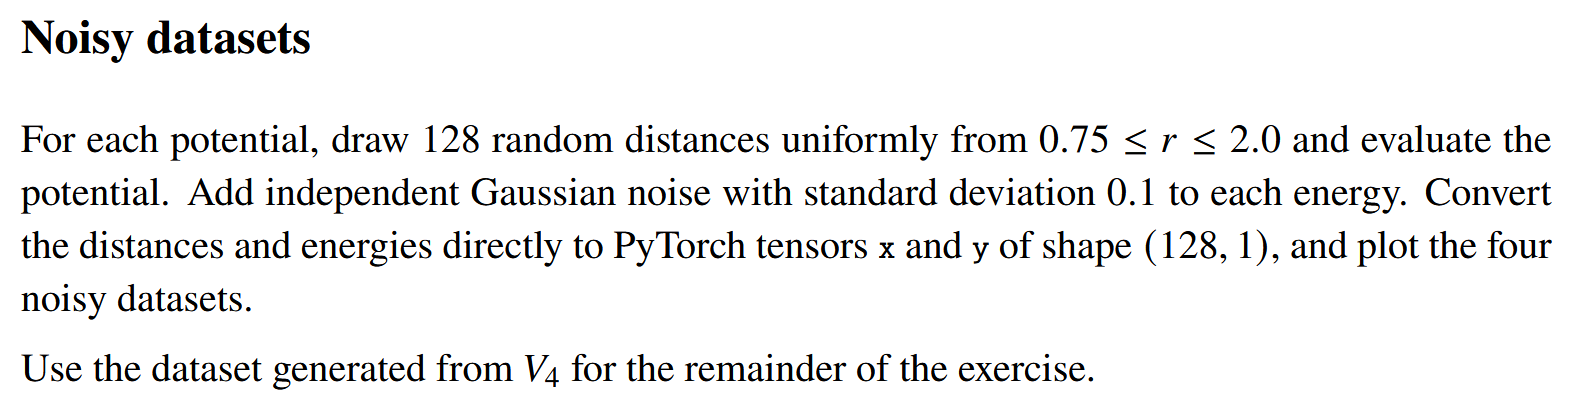

In [2]:
xs = (2.0 - 0.75) * torch.rand(128, 1) + 0.75
y_exact = V4(xs)
noise = 0.1 * torch.randn(128, 1)
ys = y_exact + noise

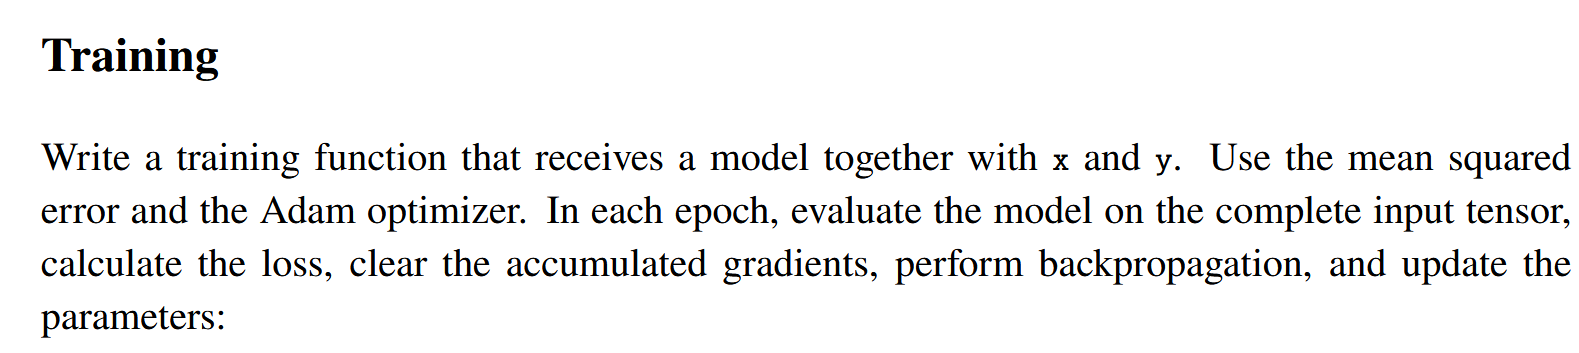
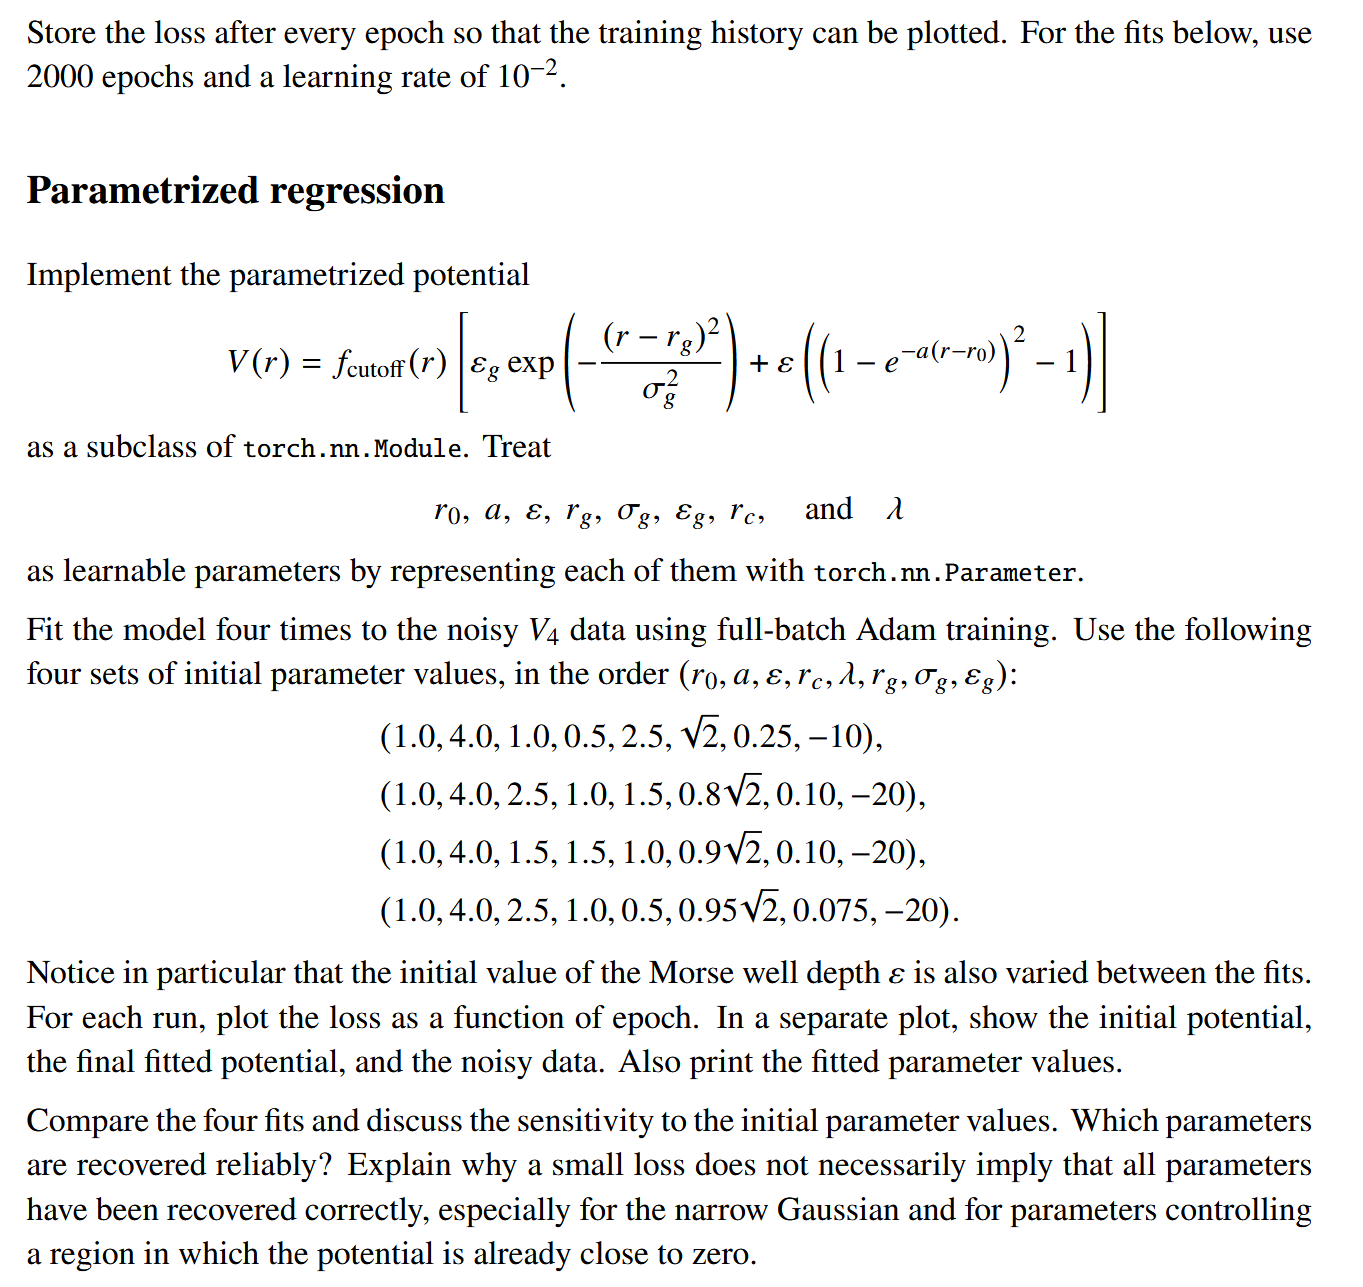


--- Fit 1 ---
r0: 0.9910, a: 4.1184, eps: 2.8747
rc: 0.3892, lambda: 2.1319
rg: 1.2812, sigma_g: -0.0022, eps_g: -9.7502


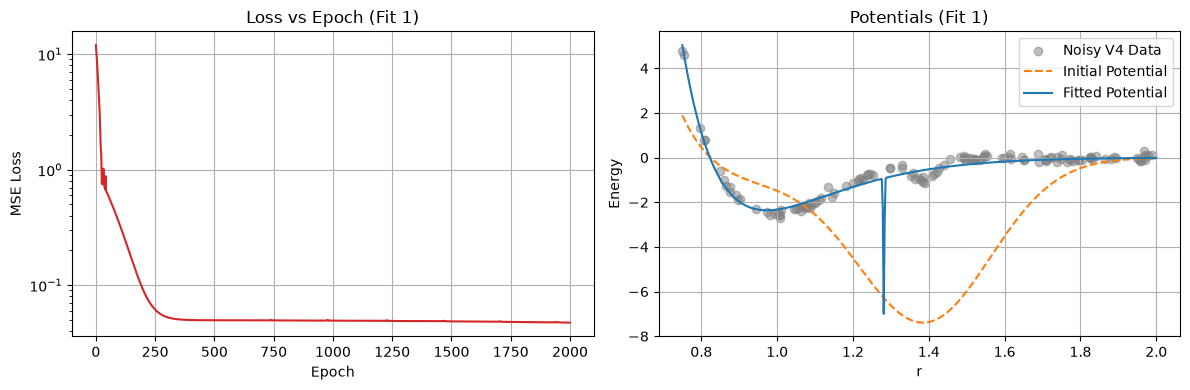


--- Fit 2 ---
r0: 1.0052, a: 3.8807, eps: 2.5972
rc: 0.8375, lambda: 0.9909
rg: 1.1675, sigma_g: -0.0037, eps_g: -19.8273


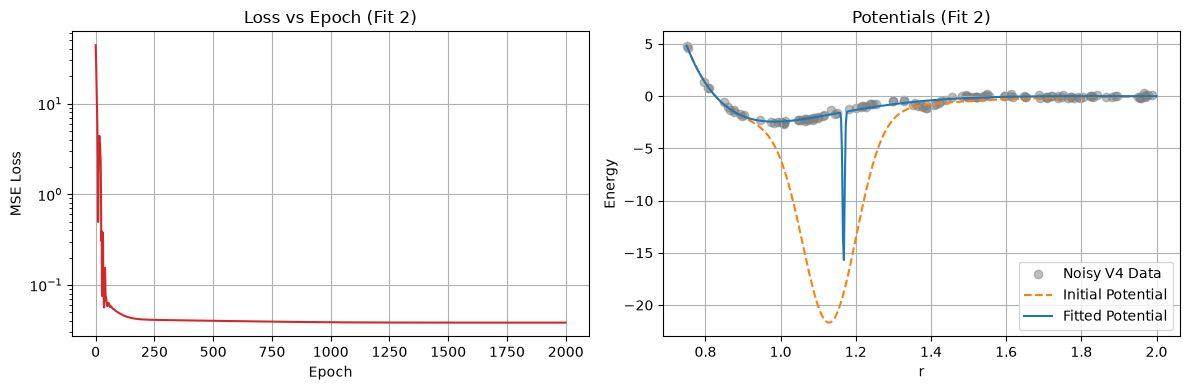


--- Fit 3 ---
r0: 1.0022, a: 3.9438, eps: 2.5493
rc: 0.8634, lambda: 0.9676
rg: 1.2687, sigma_g: 0.0008, eps_g: -19.8395


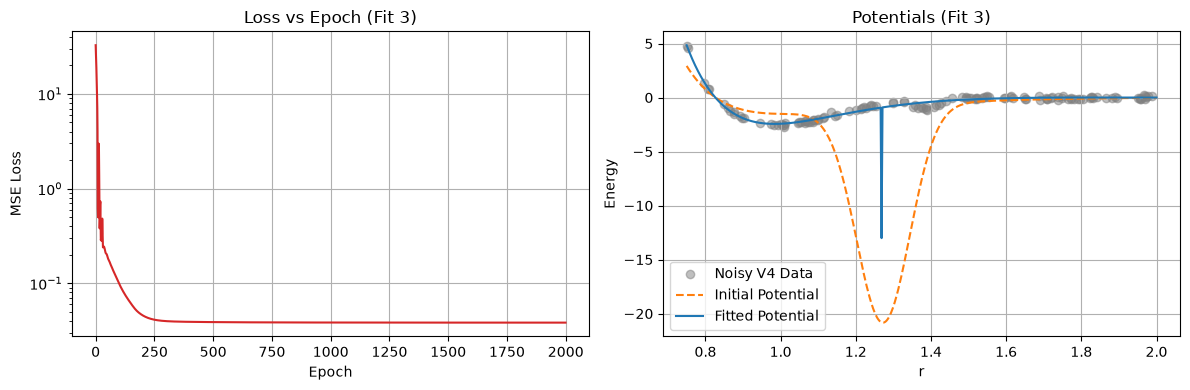


--- Fit 4 ---
r0: 1.0052, a: 3.8993, eps: 2.5092
rc: 0.9916, lambda: 0.4838
rg: 1.4282, sigma_g: -0.0576, eps_g: -19.8141


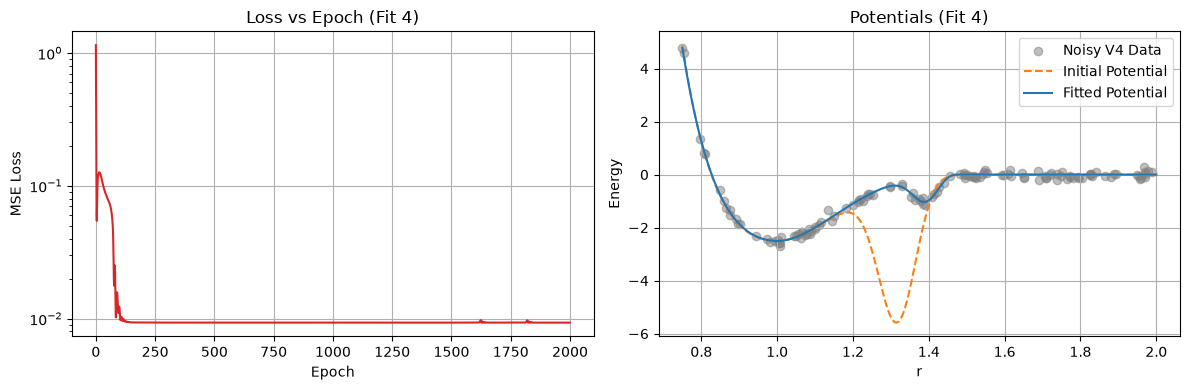

In [3]:
def train_model(model, x, y):
    loss_fn = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-2)
    
    history = []
    
    for epoch in range(2000):
        y_pred = model(x)
        loss = loss_fn(y_pred, y)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        history.append(loss.item())
        
    return history

class ParametrizedPotential(nn.Module):
    def __init__(self, r0, a, eps, rc, lambda_, rg, sigma_g, eps_g):
        super().__init__()
        self.r0 = nn.Parameter(torch.tensor(r0, dtype=torch.float32))
        self.a = nn.Parameter(torch.tensor(a, dtype=torch.float32))
        self.eps = nn.Parameter(torch.tensor(eps, dtype=torch.float32))
        self.rc = nn.Parameter(torch.tensor(rc, dtype=torch.float32))
        self.lambda_ = nn.Parameter(torch.tensor(lambda_, dtype=torch.float32))
        self.rg = nn.Parameter(torch.tensor(rg, dtype=torch.float32))
        self.sigma_g = nn.Parameter(torch.tensor(sigma_g, dtype=torch.float32))
        self.eps_g = nn.Parameter(torch.tensor(eps_g, dtype=torch.float32))

    def forward(self, r):
        v_morse = self.eps * ((1.0 - torch.exp(-self.a * (r - self.r0)))**2 - 1.0)
        v_gauss = self.eps_g * torch.exp(-((r - self.rg)**2) / (self.sigma_g**2))
        
        f_cut = torch.where(
            r <= self.rc, 
            torch.ones_like(r),
            torch.where(
                r < self.rc + self.lambda_,
                0.5 * (1.0 + torch.cos(np.pi * (r - self.rc) / self.lambda_)),
                torch.zeros_like(r)
            )
        )
        
        return f_cut * (v_gauss + v_morse)

initial_params = [
    (1.0, 4.0, 1.0, 0.5, 2.5, np.sqrt(2), 0.25, -10.0),
    (1.0, 4.0, 2.5, 1.0, 1.5, 0.8 * np.sqrt(2), 0.10, -20.0),
    (1.0, 4.0, 1.5, 1.5, 1.0, 0.9 * np.sqrt(2), 0.10, -20.0),
    (1.0, 4.0, 2.5, 1.0, 0.5, 0.95 * np.sqrt(2), 0.075, -20.0)
]

r_plot = torch.linspace(0.75, 2.0, 500).view(-1, 1)

for i, params in enumerate(initial_params):
    model = ParametrizedPotential(*params)
    y_initial = model(r_plot).detach().numpy()
    
    history = train_model(model, xs, ys)
    
    y_final = model(r_plot).detach().numpy()
    
    print(f"\n--- Fit {i+1} ---")
    print(f"r0: {model.r0.item():.4f}, a: {model.a.item():.4f}, eps: {model.eps.item():.4f}")
    print(f"rc: {model.rc.item():.4f}, lambda: {model.lambda_.item():.4f}")
    print(f"rg: {model.rg.item():.4f}, sigma_g: {model.sigma_g.item():.4f}, eps_g: {model.eps_g.item():.4f}")
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    ax1.plot(history, color='tab:red')
    ax1.set_title(f'Loss vs Epoch (Fit {i+1})')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('MSE Loss')
    ax1.set_yscale('log')
    ax1.grid(True)
    
    ax2.scatter(xs.numpy(), ys.numpy(), alpha=0.5, label='Noisy V4 Data', color='gray')
    ax2.plot(r_plot.numpy(), y_initial, '--', label='Initial Potential', color='tab:orange')
    ax2.plot(r_plot.numpy(), y_final, '-', label='Fitted Potential', color='tab:blue')
    ax2.set_title(f'Potentials (Fit {i+1})')
    ax2.set_xlabel('r')
    ax2.set_ylabel('Energy')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

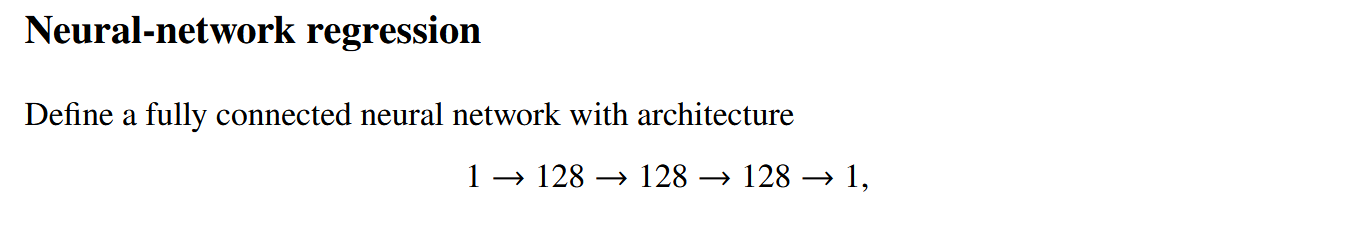
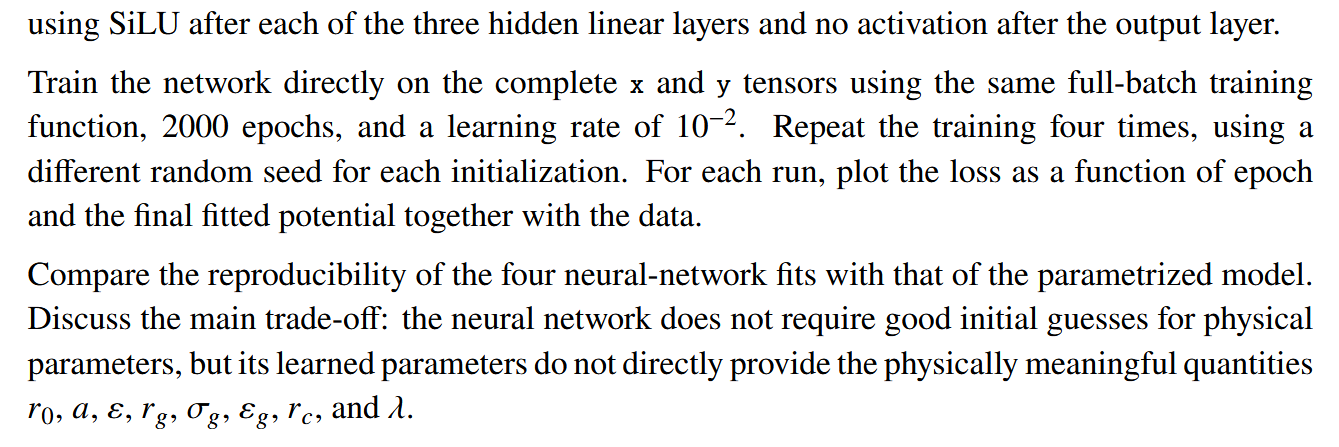

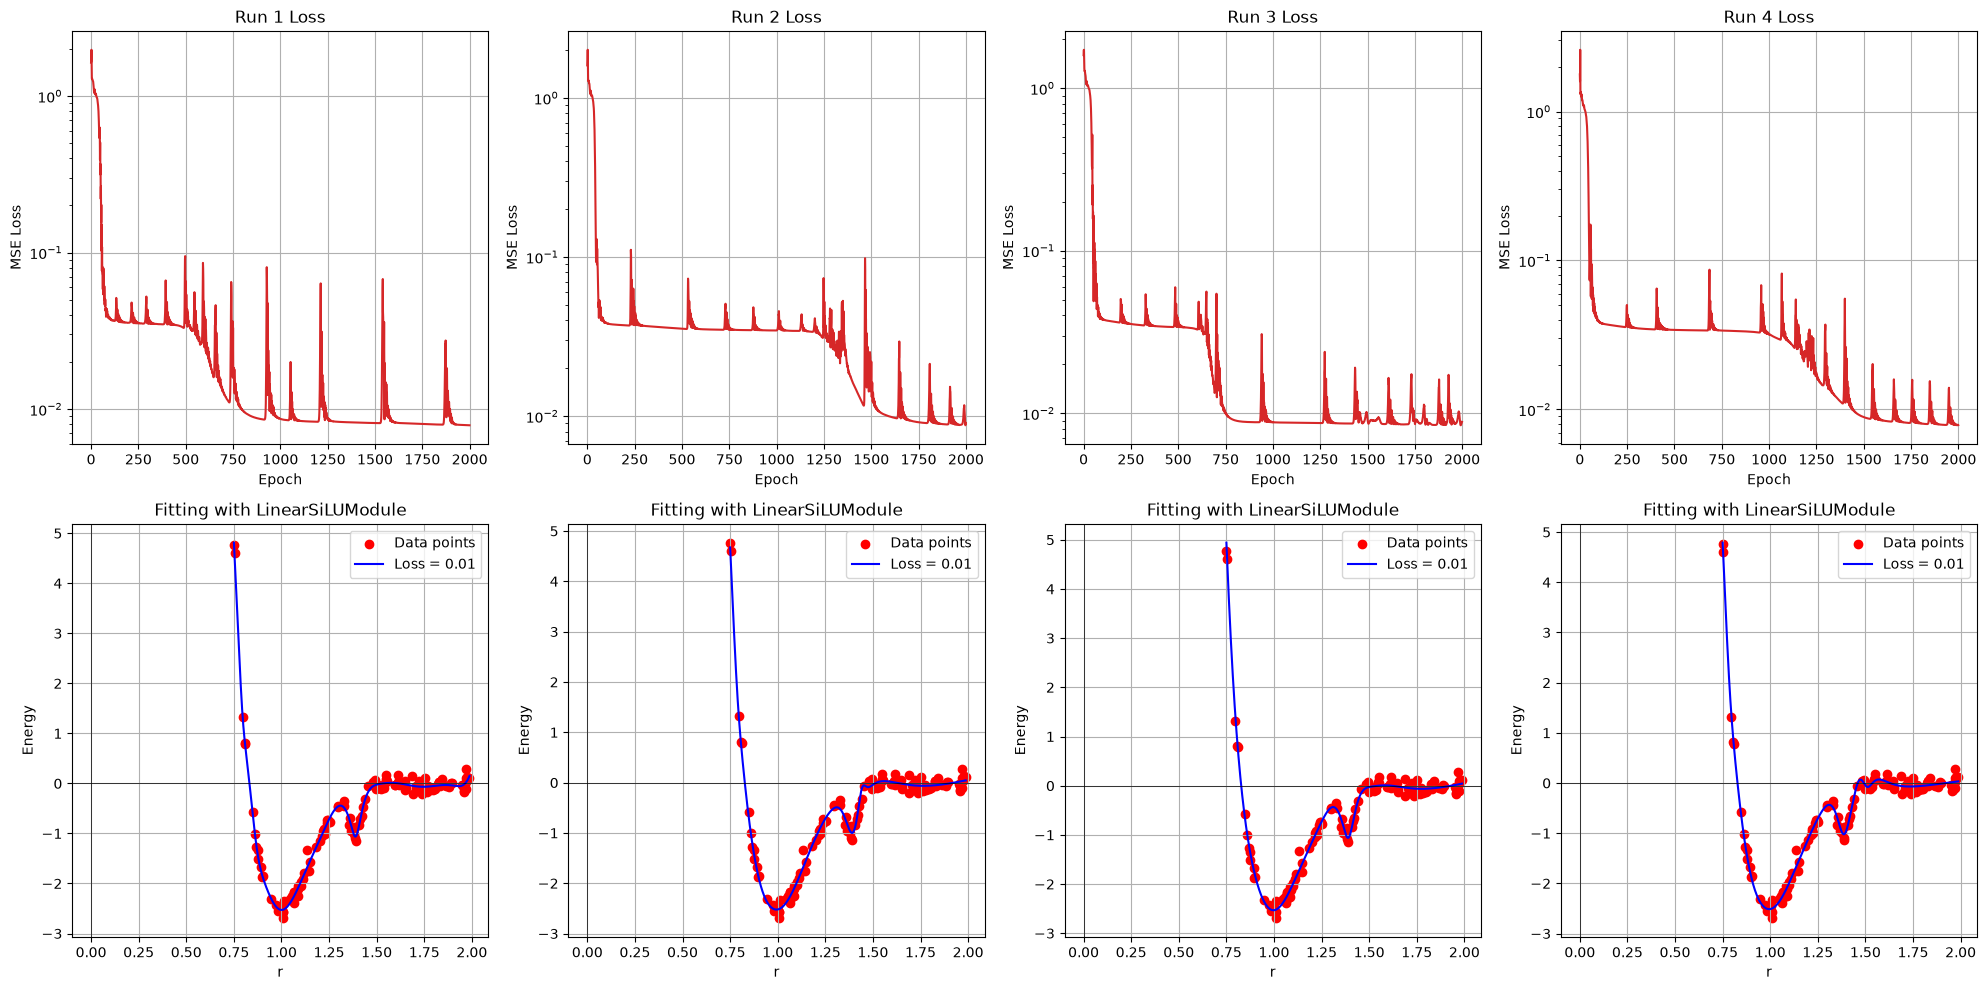

In [9]:
seeds = [42, 84, 126, 168]
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

r_plot = torch.linspace(xs.min().item(), xs.max().item(), 1000).view(-1, 1)

for i, seed in enumerate(seeds):
    torch.manual_seed(seed)
    
    model = LinearSiLUModule(hidden=128, layers=2)
    
    history = []
    loss_fn = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    
    for _ in range(2000):
        optimizer.zero_grad()
        y_pred = model(xs)
        loss = loss_fn(y_pred, ys.flatten())
        loss.backward()
        optimizer.step()
        history.append(loss.item())
        
    y_final = model(r_plot).detach().numpy()
    
    axes[0, i].plot(history, color='tab:red')
    axes[0, i].set_title(f'Run {i+1} Loss')
    axes[0, i].set_xlabel('Epoch')
    axes[0, i].set_ylabel('MSE Loss')
    axes[0, i].set_yscale('log')
    axes[0, i].grid(True)
    
    axes[1, i].scatter(xs.numpy(), ys.numpy(), color='red', label='Data points')
    axes[1, i].plot(r_plot.numpy(), y_final, color='blue', label=f'Loss = {history[-1]:.2f}')
    axes[1, i].axhline(0, color='black', linewidth=0.5)
    axes[1, i].axvline(0, color='black', linewidth=0.5)
    axes[1, i].legend()
    axes[1, i].grid(True)
    axes[1, i].set_xlabel('r')
    axes[1, i].set_ylabel('Energy')
    axes[1, i].set_title(f'Fitting with {model._get_name()}')

plt.tight_layout()
plt.show()

**Reproducibility Comparison**
The neural network fits are highly reproducible across different initializations. Regardless of the random seed used, the network converges to a nearly identical curve that maps the general shape of the data points. In contrast, the parametrized regression model from the previous exercise was extremely sensitive to its starting state, often failing to capture localized features or entirely missing the global minimum if the initial parameters were not meticulously chosen.

**The Main Trade-off**
The primary advantage of the neural network is that it does not require good initial guesses for physical parameters to achieve a highly accurate fit. It functions as a universal approximator that molds to the data automatically. However, this flexibility sacrifices interpretability; the neural network's learned parameters do not directly provide the physically meaningful quantities $r_0, a, \varepsilon, r_g, \sigma_g, \varepsilon_g, r_c$, and $\lambda$. You extract an accurate curve, but you lose the ability to read the underlying physical constants driving the interaction.